In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("C:/Users/bvsra/Desktop/smoke_detection_iot.csv")

In [4]:
df.head()

,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [5]:
df.shape

(62630, 16)

In [6]:
df.columns

Index(['Unnamed: 0', 'UTC', 'Temperature[C]', 'Humidity[%]', 'TVOC[ppb]',
       'eCO2[ppm]', 'Raw H2', 'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5',
       'NC0.5', 'NC1.0', 'NC2.5', 'CNT', 'Fire Alarm'],
      dtype='str')

In [7]:
df["Fire Alarm"].value_counts()

Fire Alarm
1    44757
0    17873
Name: count, dtype: int64

In [8]:
df.describe()

,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
count,62630.000000,6.263000e+04,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000
mean,31314.500000,1.654792e+09,15.970424,48.539499,1942.057528,670.021044,12942.453936,19754.257912,938.627649,100.594309,184.467770,491.463608,203.586487,80.049042,10511.386157,0.714626
std,18079.868017,1.100025e+05,14.359576,8.865367,7811.589055,1905.885439,272.464305,609.513156,1.331344,922.524245,1976.305615,4265.661251,2214.738556,1083.383189,7597.870997,0.451596
min,0.000000,1.654712e+09,-22.010000,10.740000,0.000000,400.000000,10668.000000,15317.000000,930.852000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,15657.250000,1.654743e+09,10.994250,47.530000,130.000000,400.000000,12830.000000,19435.000000,938.700000,1.280000,1.340000,8.820000,1.384000,0.033000,3625.250000,0.000000
50%,31314.500000,1.654762e+09,20.130000,50.150000,981.000000,400.000000,12924.000000,19501.000000,938.816000,1.810000,1.880000,12.450000,1.943000,0.044000,9336.000000,1.000000
75%,46971.750000,1.654778e+09,25.409500,53.240000,1189.000000,438.000000,13109.000000,20078.000000,939.418000,2.090000,2.180000,14.420000,2.249000,0.051000,17164.750000,1.000000
max,62629.000000,1.655130e+09,59.930000,75.200000,60000.000000,60000.000000,13803.000000,21410.000000,939.861000,14333.690000,45432.260000,61482.030000,51914.680000,30026.438000,24993.000000,1.000000


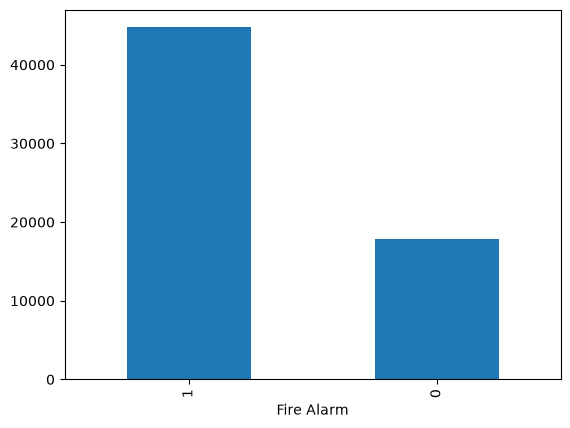

In [28]:
import matplotlib.pyplot as plt
df["Fire Alarm"].value_counts().plot(kind="bar")
plt.savefig("sinif_dagilimi.png")

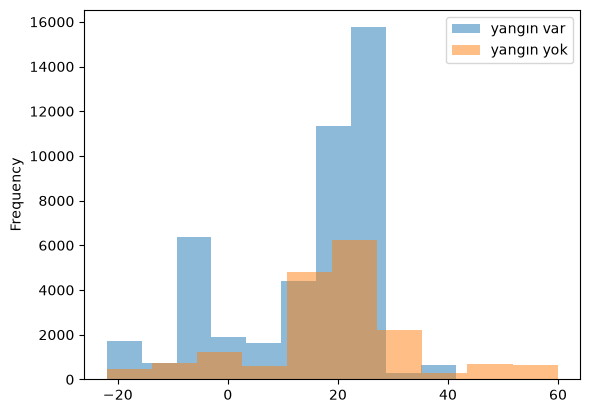

In [10]:
df[df["Fire Alarm"]==1]["Temperature[C]"].plot(kind="hist", alpha=0.5)
df[df["Fire Alarm"]==0]["Temperature[C]"].plot(kind="hist", alpha=0.5)
plt.legend(["yangın var","yangın yok"])
plt.savefig("sicaklik_karsilastirma.png")

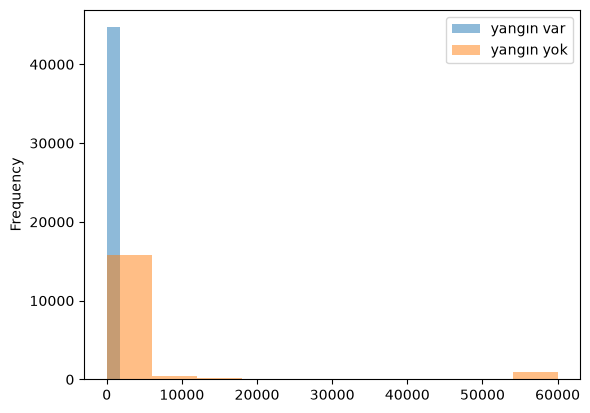

In [11]:
df[df["Fire Alarm"]==1]["TVOC[ppb]"].plot(kind="hist", alpha=0.5)
df[df["Fire Alarm"]==0]["TVOC[ppb]"].plot(kind="hist", alpha=0.5)
plt.legend(["yangın var","yangın yok"])
plt.savefig("tvoc_karsilastirma.png")

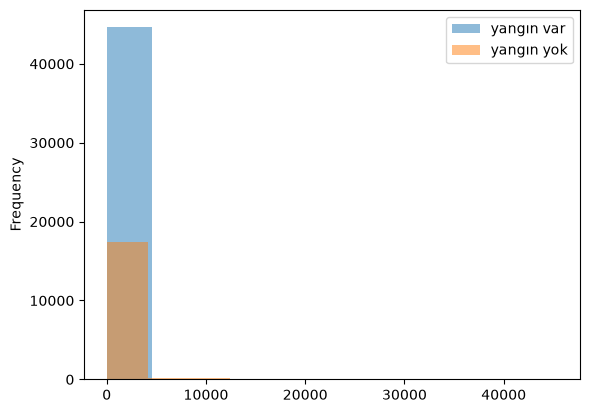

In [12]:
df[df["Fire Alarm"]==1]["PM2.5"].plot(kind="hist", alpha=0.5)
df[df["Fire Alarm"]==0]["PM2.5"].plot(kind="hist", alpha=0.5)
plt.legend(["yangın var","yangın yok"])
plt.savefig("pm_karsilastirma.png")

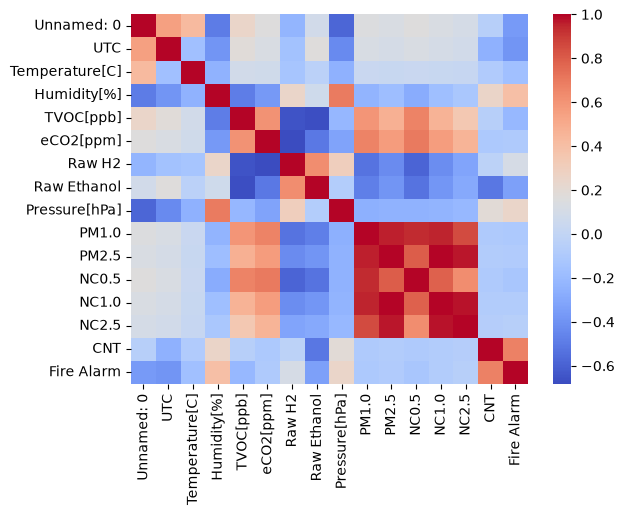

In [13]:
import seaborn as sns
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.savefig("korelasyon.png")

In [23]:
df = df.drop(columns=[c for c in df.columns if c in ["Unnamed: 0", "UTC", "CNT"]])

In [24]:
df.columns

Index(['Temperature[C]', 'Humidity[%]', 'TVOC[ppb]', 'eCO2[ppm]', 'Raw H2',
       'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0',
       'NC2.5', 'Fire Alarm'],
      dtype='str')

Unnamed: 0 sütunu satır numarasıdır, UTC sütunu zaman damgasıdır, CNT sütunu örnek sayacıdır. Üçü de yangınla ilgisizdir ama modele verilirse model 'sıralamadan' tahmin yapmayı öğrenir ve sahte yüksek skor üretir. Bu yüzden üçünü de eğitimden attık.